# Análise do impacto da ventania de 07/11/2026 sobre a manutenção de árvores em Curitiba

## Contexto
A cidade de Curitiba foi afetada por uma forte ventania no dia 07/11/2026, o que gerou uma série de ocorrências relacionadas a queda de árvores em vias públicas, bloqueio de passagem e riscos à mobilidade urbana. Nesse cenário, o estudo busca avaliar se a prefeitura já havia sido alertada previamente sobre riscos de poda em locais que posteriormente sofreram quedas durante o evento climático.

A análise parte da hipótese de que parte dos incidentes poderia ter sido evitada por meio de manutenção preventiva em árvores que já estavam em fila de atendimento, mas que não foram atendidas antes da tempestade. Com isso, o trabalho investiga a relação entre pedidos de poda em aberto antes do evento e as quedas registradas logo após a ventania.

## Objetivo da análise
O objetivo geral deste trabalho é verificar a existência de sobreposição entre:
- pedidos de poda de árvores em aberto antes da ventania;
- registros de árvores caídas após o evento;
- regiões, bairros e ruas com maior concentração de alertas ignorados.

Mais especificamente, busca-se responder se a ocorrência de quedas de árvores em determinadas ruas e bairros estava associada a pedidos anteriores de manutenção preventiva que não foram atendidos.

## Perguntas de pesquisa
1. Quantos pedidos de poda em árvores estavam abertos antes da ventania?
2. Quantas ocorrências de queda de árvore foram registradas após o evento?
3. Quantas dessas ocorrências ocorreram em ruas que já possuíam pedidos de poda em aberto?
4. Quantas ruas únicas foram afetadas por esse passivo?
5. Em quais regiões e bairros esse padrão foi mais concentrado?
6. O cruzamento entre pedidos de poda e quedas evidencia negligência na manutenção preventiva?

## Base de dados
A análise foi realizada com dados do sistema de atendimento 156 da Prefeitura de Curitiba, considerando:
- solicitações relacionadas ao assunto “Árvore”;
- pedidos de poda em aberto antes do dia 07/11/2026;
- chamados de queda ou galho caído após a ventania;
- dados geográficos e de bairro/regional para comparar os registros espacialmente.

A base foi tratada para padronizar nomes de logradouros, remover ruídos textuais, separar pedidos antes e depois do evento e comparar ocorrências por rua e bairro.

## Metodologia
A metodologia adotada inclui:
- filtragem dos registros por assunto e período;
- separação da base em dois grupos: antes e depois da ventania;
- normalização de nomes de logradouros para permitir comparação;
- cruzamento entre ruas com pedido de poda e ruas com quedas de árvore;
- agregação por regional e bairro para identificar os locais mais afetados;
- análise geoespacial com cruzamento entre os dados do 156 e a malha viária da cidade.

## Indicadores principais
Ao longo do estudo, serão utilizados indicadores como:
- total de pedidos de poda em aberto;
- total de ocorrências de queda após a ventania;
- número de ruas com interseção entre alerta prévio e queda;
- número de ruas únicas afetadas;
- distribuição por regional e bairro;
- mapeamento dos trechos urbanos com maior risco de impacto.

## Importância do estudo
Este trabalho tem relevância tanto técnica quanto institucional, pois permite quantificar o impacto do atraso na manutenção preventiva de árvores e demonstrar, com base em dados públicos, o potencial efeito de decisões de manutenção e priorização de serviços. Os resultados podem subsidiar relatórios de gestão, ações preventivas e estratégias de manutenção urbana em áreas de risco.

## Conclusão preliminar
A análise sugere que uma parcela relevante dos eventos de queda de árvores ocorreu em locais que já haviam sido sinalizados previamente à prefeitura por meio de pedidos de poda. Esse padrão indica a existência de um passivo de manutenção que pode ter contribuído diretamente para o agravamento dos impactos da ventania. A continuidade da análise se concentra em mensurar esse efeito por região, bairro e rua, buscando identificar a extensão real do risco não mitigado antes do evento.

In [164]:
# importar pacotes necessários
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
import geopandas as gpd
import folium

In [159]:
# Abrindo arquivo csv e limpeza coluna vazia
df = pd.read_csv("2026-11-08_156_-_Base_de_Dados.csv", sep = ";", encoding = "utf-8")
df.drop(columns=['Unnamed: 11'], inplace=True)

#Selecionando apenas pedidos envolvidos com assunto "Árvore" para análise
df_arvores = df[df['Assunto'] == 'Árvore']


C:\Users\letre\AppData\Local\Temp\ipykernel_15196\586775116.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Unnamed: 11'], inplace=True)


##### Separando pedidos por data, sendo antes e após ventania dia 07/11/2026

In [160]:
# 0. Converter para datetime e isolar APENAS os dados do ano de 2026
df_arvores['DataCriacao'] = pd.to_datetime(df_arvores['DataCriacao'], format='%d/%m/%Y')
df_arvores = df_arvores[df_arvores['DataCriacao'].dt.year == 2026]

# 1. Separar dataset por data usando .copy() para evitar o erro de memória do Pandas
data_vendaval = pd.to_datetime('07/11/2026', format='%d/%m/%Y')
df_arvores_antes = df_arvores[df_arvores['DataCriacao'] < data_vendaval].copy()
df_arvores_depois = df_arvores[df_arvores['DataCriacao'] >= data_vendaval].copy()

# 2. Filtrar DEPOIS: apenas quedas com ou sem bloqueio
df_arvores_depois = df_arvores_depois[df_arvores_depois["Subdivisao"].isin([
    "Árvore ou galho caído – com bloqueio de passagem", 
    "Árvore ou galho caído – sem bloqueio de passagem"
])]

# 3. Filtrar ANTES: apenas situações "Aberto" E subdivisões corretas
df_arvores_antes = df_arvores_antes[df_arvores_antes["Situacao"] == "Aberto"]
df_arvores_antes = df_arvores_antes[df_arvores_antes["Subdivisao"].isin([
    "Poda de manutenção em árvores", 
    "Avaliação para corte em via pública"
])]

# 4. Guardar com os nomes EXATOS que serão lidos na próxima etapa
df_arvores_depois.to_csv('df_arvores_depois.csv', index=False, sep=';', encoding='utf-8')
df_arvores_antes.to_csv('df_arvores_antes_aberto.csv', index=False, sep=';', encoding='utf-8')

print("Filtros aplicados e ficheiros CSV guardados com sucesso!")

Filtros aplicados e ficheiros CSV guardados com sucesso!


#### Limpeza de lougradouro para possibilitar avaliação de sobreposição

In [161]:

# 1. Carregar as bases filtradas
df_antes = pd.read_csv('df_arvores_antes.csv', sep=';', encoding='utf-8')
df_depois = pd.read_csv('df_arvores_depois.csv', sep=';', encoding='utf-8')

# 2. Criar uma coluna sinalizadora para facilitar a separação futura
df_antes['grupo_analise'] = 'antes_poda'
df_depois['grupo_analise'] = 'depois_queda'

# 3. Concatenar os datasets
df_arvores = pd.concat([df_antes, df_depois], ignore_index=True)

# 4. Função de limpeza do Logradouro
def limpar_logradouro(endereco):
    if pd.isna(endereco):
        return ""
    
    # Maiúsculas e remoção de acentos
    rua = str(endereco).upper().strip()
    rua = ''.join(c for c in unicodedata.normalize('NFD', rua) if unicodedata.category(c) != 'Mn')
    
    # Remover prefixos comuns de Curitiba
    prefixos = [r'^RUA\s+', r'^R\s+', r'^AVENIDA\s+', r'^AV\s+', r'^TRAVESSA\s+', r'^TR\s+', r'^PRACA\s+', r'^PC\s+', r'^ALAMEDA\s+', r'^AL\s+']
    for prefixo in prefixos:
        rua = re.sub(prefixo, '', rua)
        
    # Limpar pontuações residuais substituindo por espaço
    rua = re.sub(r'[.,;-]', ' ', rua)
    
    # Remover espaços duplos acidentais
    rua = re.sub(r'\s+', ' ', rua).strip()
    
    return rua

# 5. Aplicar a função diretamente na coluna Logradouro
df_arvores['Logradouro_Limpo'] = df_arvores['Logradouro'].apply(limpar_logradouro)

# Visualizar o resultado da limpeza
display(df_arvores[['Logradouro', 'Logradouro_Limpo', 'Bairro', 'grupo_analise']].head(10))

,Logradouro,Logradouro_Limpo,Bairro,grupo_analise
0,Rua Antônio Boza,ANTONIO BOZA,SITIO CERCADO,antes_poda
1,Valdomiro Silveira,VALDOMIRO SILVEIRA,BOA VISTA,antes_poda
2,Rio Norte Belém,RIO NORTE BELEM,SAO LOURENCO,antes_poda
3,RUA ADA MACAGGI,ADA MACAGGI,BAIRRO ALTO,antes_poda
4,Presidente Taunay,PRESIDENTE TAUNAY,BATEL,antes_poda
5,RUA SÃO CRISTÓVÃO,SAO CRISTOVAO,GUAIRA,antes_poda
6,RUA SOLDADO JORGE COLACO BARROS,SOLDADO JORGE COLACO BARROS,ALTO BOQUEIRAO,antes_poda
7,Rua Major Nestor Luiz de Oliveira Júnior,MAJOR NESTOR LUIZ DE OLIVEIRA JUNIOR,SANTO INACIO,antes_poda
8,Aristides Marquezini,ARISTIDES MARQUEZINI,SITIO CERCADO,antes_poda
9,Rua Presidente Rodrigo Otávio,PRESIDENTE RODRIGO OTAVIO,CRISTO REI,antes_poda


## ANÁLISE DE SOBREPOSIÇÃO DE PEDIDOS

In [162]:
# 1. Separar os datasets limpos utilizando a coluna sinalizadora
df_poda = df_arvores[df_arvores['grupo_analise'] == 'antes_poda'].copy()
df_queda = df_arvores[df_arvores['grupo_analise'] == 'depois_queda'].copy()

# 2. Realizar o cruzamento (Inner Join) por Rua e Bairro
# Isso trará apenas os registros onde a mesma rua e bairro aparecem em AMBAS as bases
df_cruzamento = pd.merge(
    df_poda, 
    df_queda, 
    on=['Logradouro_Limpo', 'Bairro'], 
    suffixes=('_poda', '_queda'), 
    how='inner'
)

# 3. Remover duplicatas para descobrir exatamente quantas ruas únicas foram afetadas
ruas_alerta_ignorado = df_cruzamento[['Logradouro_Limpo', 'Bairro']].drop_duplicates()

# 4. Exibir os resultados finais que respondem às perguntas do impacto da ventania

print("--- RESULTADOS DA ANÁLISE DE IMPACTO ---")
print(f"1. Total de pedidos de poda em aberto (antes de 07/11): {len(df_poda)}")
print(f"2. Total de chamados de queda (após a ventania de 07/11): {len(df_queda)}")
print(f"3. Número de ocorrências de quedas em locais que JÁ TINHAM pedido de poda: {len(df_cruzamento)}")
print(f"4. Total de RUAS ÚNICAS afetadas por esse passivo: {len(ruas_alerta_ignorado)}")

--- RESULTADOS DA ANÁLISE DE IMPACTO ---
1. Total de pedidos de poda em aberto (antes de 07/11): 14756
2. Total de chamados de queda (após a ventania de 07/11): 741
3. Número de ocorrências de quedas em locais que JÁ TINHAM pedido de poda: 5090
4. Total de RUAS ÚNICAS afetadas por esse passivo: 253


## traduzindo

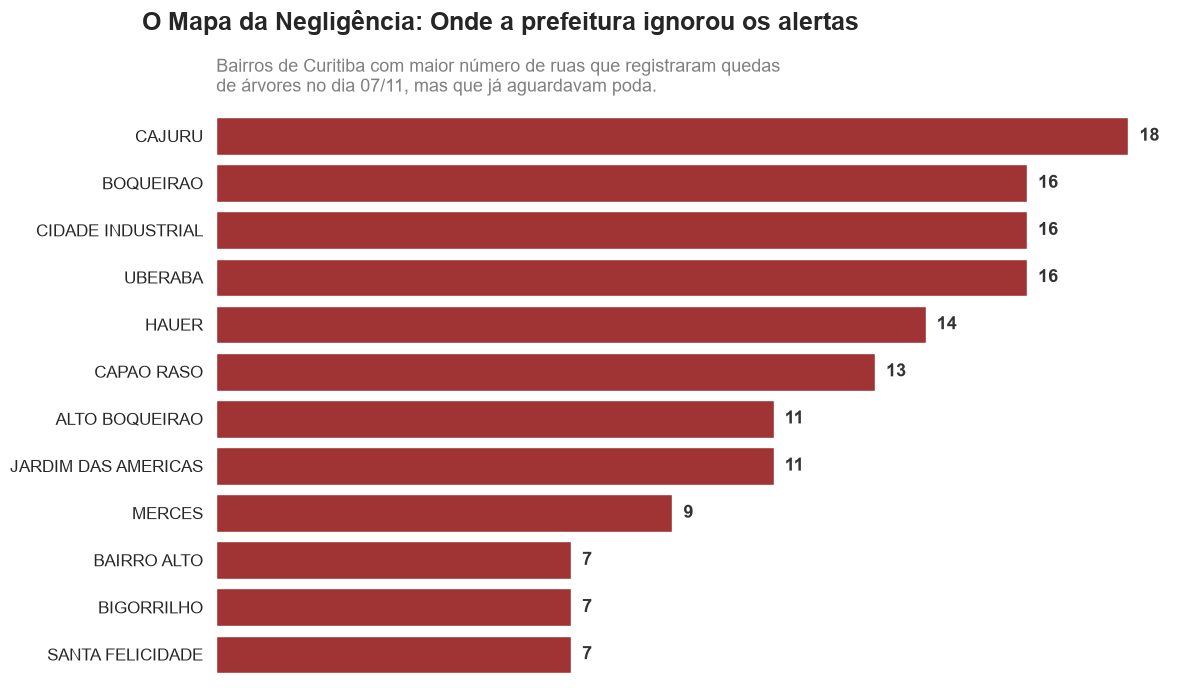

In [138]:
# 1. Pegar os Top 10 ou Top 12 bairros para não poluir a imagem
top_bairros = analise_bairro.head(12)

# 2. Configurar o estilo visual "Limpo" (Clean)
sns.set_theme(style="white")
plt.figure(figsize=(12, 7))

# 3. Criar as barras com uma cor de "Alerta/Perigo" (Vermelho escuro)
ax = sns.barplot(
    data=top_bairros, 
    x='Ruas_Unicas_Afetadas', 
    y='Bairro', 
    color='#b22222'
)

# 4. Adicionar os números grandes exatamente na ponta de cada barra
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", 
                (p.get_width(), p.get_y() + p.get_height() / 2.), 
                xytext=(8, 0), textcoords='offset points', 
                va='center', fontsize=13, fontweight='bold', color='#333333')

# 5. Remover linhas, bordas e eixos desnecessários (Design Jornalístico)
sns.despine(left=True, bottom=True)
ax.set(xticklabels=[], xlabel='', ylabel='')
ax.tick_params(axis='y', labelsize=12, left=False)

# 6. Título que conta a história (Manchete + Subtítulo)
plt.suptitle('O Mapa da Negligência: Onde a prefeitura ignorou os alertas', fontsize=18, fontweight='bold', x=0.125, y=0.98, ha='left')
plt.title('Bairros de Curitiba com maior número de ruas que registraram quedas\nde árvores no dia 07/11, mas que já aguardavam poda.', fontsize=13, color='gray', loc='left', pad=15)

# Salvar em alta resolução para enviar ao jornal
plt.tight_layout()
plt.savefig('grafico_imprensa_bairros.png', dpi=300, bbox_inches='tight')
plt.show()

In [168]:
# 1. Função Universal de Limpeza (Para garantir que as duas bases fiquem idênticas)
def limpar_nome_universal(nome):
    if pd.isna(nome): return ""
    
    # Maiúsculas e sem acentos
    texto = str(nome).upper()
    texto = ''.join(c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn')
    
    # Trocar pontuações por espaço (Resolve o problema do "R." grudado no IPPUC)
    texto = re.sub(r'[.,;-]', ' ', texto)
    
    # Normalizar espaços duplos
    texto = re.sub(r'\s+', ' ', texto).strip()
    
    # Remover prefixos de logradouro
    texto = re.sub(r'^(RUA|R|AVENIDA|AV|TRAVESSA|TR|PRACA|PC|ALAMEDA|AL|RODOVIA|ROD|ESTRADA|EST)\s+', '', texto)
    
    return texto.strip()

# 2. Aplicar a limpeza universal nas bases do 156
ruas_poda = df_poda[['Logradouro_Limpo']].drop_duplicates().copy()
ruas_poda['Logradouro_Limpo'] = ruas_poda['Logradouro_Limpo'].apply(limpar_nome_universal)

ruas_queda = df_queda[['Logradouro_Limpo']].drop_duplicates().copy()
ruas_queda['Logradouro_Limpo'] = ruas_queda['Logradouro_Limpo'].apply(limpar_nome_universal)

ruas_cruzamento = df_cruzamento[['Logradouro_Limpo']].drop_duplicates().copy()
ruas_cruzamento['Logradouro_Limpo'] = ruas_cruzamento['Logradouro_Limpo'].apply(limpar_nome_universal)

# 3. Preparar o Shapefile do IPPUC (Combinação crucial de colunas)
# Se a NMVIA for nula, ele preenche com a NMVIA_ANT.
gdf_ruas['Nome_Combinado'] = gdf_ruas['NMVIA'].fillna(gdf_ruas['NMVIA_ANT']).fillna("")
gdf_ruas['Nome_Limpo_Shape'] = gdf_ruas['Nome_Combinado'].apply(limpar_nome_universal)

# 4. Refazer o Cruzamento Vetorial
gdf_poda_mapa = gdf_ruas.merge(ruas_poda, left_on='Nome_Limpo_Shape', right_on='Logradouro_Limpo', how='inner')
gdf_queda_mapa = gdf_ruas.merge(ruas_queda, left_on='Nome_Limpo_Shape', right_on='Logradouro_Limpo', how='inner')
gdf_cruzamento_mapa = gdf_ruas.merge(ruas_cruzamento, left_on='Nome_Limpo_Shape', right_on='Logradouro_Limpo', how='inner')

# 5. Checar os volumes no terminal
print(f"Ruas para Poda (Azul): {len(gdf_poda_mapa)}")
print(f"Ruas para Queda (Vermelho): {len(gdf_queda_mapa)}")
print(f"Ruas de Cruzamento (Roxo): {len(gdf_cruzamento_mapa)}")

# 6. Gerar o Mapa Corrigido
mapa_curitiba = folium.Map(
    location=[-25.4284, -49.2733], 
    zoom_start=12, 
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri &mdash; Esri, DeLorme, NAVTEQ'
)

# Adicionar Camada AZUL (weight=2 para linha fina)
if not gdf_poda_mapa.empty:
    folium.GeoJson(
        gdf_poda_mapa,
        name='1. Pedidos de Poda (Antes 07/11)',
        style_function=lambda x: {'color': 'blue', 'weight': 2, 'opacity': 0.4},
        tooltip=folium.GeoJsonTooltip(fields=['Nome_Combinado'], aliases=['Poda Pendente:'])
    ).add_to(mapa_curitiba)

# Adicionar Camada VERMELHA (weight=4 para visibilidade intermediária)
if not gdf_queda_mapa.empty:
    folium.GeoJson(
        gdf_queda_mapa,
        name='2. Quedas de Árvores (Após 07/11)',
        style_function=lambda x: {'color': 'red', 'weight': 2, 'opacity': 0.7},
        tooltip=folium.GeoJsonTooltip(fields=['Nome_Combinado'], aliases=['Queda de Árvore:'])
    ).add_to(mapa_curitiba)

# Adicionar Camada ROXA (weight=5 para destaque da negligência)
if not gdf_cruzamento_mapa.empty:
    folium.GeoJson(
        gdf_cruzamento_mapa,
        name='3. Alertas Ignorados (Poda + Queda)',
        style_function=lambda x: {'color': 'purple', 'weight': 5, 'opacity': 1.0},
        tooltip=folium.GeoJsonTooltip(fields=['Nome_Combinado'], aliases=['ALERTA IGNORADO:'])
    ).add_to(mapa_curitiba)

folium.LayerControl().add_to(mapa_curitiba)
mapa_curitiba.save('mapa_alertas_curitiba.html')

Ruas para Poda (Azul): 20132
Ruas para Queda (Vermelho): 2414
Ruas de Cruzamento (Roxo): 2166
